
# Customer Churn Prediction in E-Commerce

## 1. Project Overview

Customer churn is a major challenge for e-commerce businesses, as retaining existing customers is often essential for maintaining long-term profitability.

This project aims to analyze customer purchasing behavior and develop machine learning models capable of identifying customers at risk of becoming inactive.

The analysis uses historical transaction records from the Online Retail dataset.

## 2. Project Objectives

- Examine and assess the quality of the transaction data.
- Identify missing values, duplicates, inconsistencies and unusual observations.
- Develop customer-level behavioral features using Recency, Frequency and Monetary (RFM) analysis.
- Construct a time-based customer inactivity target.
- Develop and compare Random Forest and XGBoost classifiers.
- Evaluate model performance using appropriate classification metrics.
- Translate model predictions into practical customer retention recommendations.

## 3. Methodology

The project follows four main stages:

1. Data Exploration and Cleaning
2. Feature Engineering
3. Model Development and Evaluation
4. Business Insights and Recommendations

The dataset does not contain an explicit churn label. Therefore, customer inactivity will be defined using a historical observation period and a subsequent prediction window.

Model performance will be evaluated using business-relevant metrics rather than accuracy alone.


In [26]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn
import xgboost
import shap

print("Python version:", sys.version.split()[0])
print("Python interpreter:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)
print("\nEnvironment verification completed.")

Python version: 3.12.16
Python interpreter: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/.venv312/bin/python
Pandas: 3.1.1
NumPy: 2.5.5
Scikit-learn: 1.9.1
XGBoost: 3.4.1
SHAP: 0.54.1

Environment verification completed.


In [27]:
from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

possible_paths = [
    Path("data.csv"),
    Path("../data.csv")
]

data_path = next(
    (path.resolve() for path in possible_paths if path.is_file()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        f"data.csv not found. Current directory: {Path.cwd()}"
    )

df = pd.read_csv(data_path, encoding="ISO-8859-1")

print("Dataset loaded successfully.")
print(f"Dataset location: {data_path}")
print(f"Number of records: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

display(df.head())

Dataset loaded successfully.
Dataset location: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/data.csv
Number of records: 541,909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom




This section examines the structure, dimensions, data types and statistical characteristics of the original dataset. The objective is to understand the information available and identify potential data quality concerns before performing any preprocessing.


In [28]:
print("Dataset dimensions:", df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset dimensions: (541909, 8)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())
print("Invalid dates:", df["InvoiceDate"].isna().sum())

Earliest transaction: 2010-12-01 08:26:00
Latest transaction: 2011-12-09 12:50:00
Invalid dates: 0


In [30]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().mean() * 100).round(2)
})

quality_summary = pd.DataFrame({
    "Issue": [
        "Duplicate records",
        "Negative quantities",
        "Zero unit prices",
        "Negative unit prices",
        "Cancellation invoices"
    ],
    "Count": [
        df.duplicated().sum(),
        (df["Quantity"] < 0).sum(),
        (df["UnitPrice"] == 0).sum(),
        (df["UnitPrice"] < 0).sum(),
        df["InvoiceNo"].astype(str).str.startswith("C").sum()
    ]
})

display(missing_summary)
display(quality_summary)

,Missing Values,Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


,Issue,Count
0,Duplicate records,5268
1,Negative quantities,10624
2,Zero unit prices,2515
3,Negative unit prices,2
4,Cancellation invoices,9288



## 5. Investigation of Transaction Anomalies

This section examines unusual transaction records, including cancelled invoices, negative quantities, zero-priced items and duplicate transactions.

The purpose is to distinguish genuine purchasing activity from returns, cancellations and potentially erroneous records before constructing customer-level behavioral features.


In [31]:
invoice_no = df["InvoiceNo"].astype("string").str.strip()

is_cancellation = invoice_no.str.startswith("C", na=False)
is_negative_quantity = df["Quantity"] < 0

overlap_summary = pd.crosstab(
    is_cancellation.map({
        True: "Cancellation invoice",
        False: "Regular invoice"
    }),
    is_negative_quantity.map({
        True: "Negative quantity",
        False: "Non-negative quantity"
    }),
    margins=True
)

display(overlap_summary)

Quantity,Negative quantity,Non-negative quantity,All
InvoiceNo,,,
Cancellation invoice,9288,0,9288
Regular invoice,1336,531285,532621
All,10624,531285,541909


In [32]:
print("Cancellation invoice examples:")
display(df.loc[
    is_cancellation,
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID"]
].head(10))

print("\nNegative quantities without a cancellation invoice:")
display(df.loc[
    is_negative_quantity & ~is_cancellation,
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID"]
].head(10))

print("\nTransactions with zero or negative prices:")
display(df.loc[
    df["UnitPrice"] <= 0,
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID"]
].head(15))

Cancellation invoice examples:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
141,C536379,D,Discount,-1,27.50,"14,527.00"
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,"15,311.00"
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,"17,548.00"
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,"17,548.00"
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,"17,548.00"
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,"17,548.00"
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,"17,548.00"
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,"17,548.00"
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,"17,548.00"
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,"17,897.00"



Negative quantities without a cancellation invoice:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
2406,536589,21777,NaN,-10,0.00,NaN
4347,536764,84952C,NaN,-38,0.00,NaN
7188,536996,22712,NaN,-20,0.00,NaN
7189,536997,22028,NaN,-20,0.00,NaN
7190,536998,85067,NaN,-6,0.00,NaN
7192,537000,21414,NaN,-22,0.00,NaN
7193,537001,21653,NaN,-6,0.00,NaN
7195,537003,85126,NaN,-2,0.00,NaN
7196,537004,21814,NaN,-30,0.00,NaN
7197,537005,21692,NaN,-70,0.00,NaN



Transactions with zero or negative prices:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
622,536414,22139,NaN,56,0.00,NaN
1970,536545,21134,NaN,1,0.00,NaN
1971,536546,22145,NaN,1,0.00,NaN
1972,536547,37509,NaN,1,0.00,NaN
1987,536549,85226A,NaN,1,0.00,NaN
1988,536550,85044,NaN,1,0.00,NaN
2024,536552,20950,NaN,1,0.00,NaN
2025,536553,37461,NaN,3,0.00,NaN
2026,536554,84670,NaN,23,0.00,NaN
2406,536589,21777,NaN,-10,0.00,NaN


In [33]:
duplicate_rows = df[
    df.duplicated(keep=False)
].sort_values(["InvoiceNo", "StockCode", "InvoiceDate"])

display(duplicate_rows.head(15))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,"17,908.00",United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,"17,908.00",United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,"17,920.00",United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,"17,920.00",United Kingdom


In [34]:
duplicate_mask = df.duplicated(keep=False)

duplicate_groups = (
    df.groupby(df.columns.tolist(), dropna=False)
    .size()
    .loc[lambda x: x > 1]
    .sort_values(ascending=False)
)

print("Rows involved in duplicate groups:", duplicate_mask.sum())
print("Excess duplicate rows:", df.duplicated().sum())
print("Number of duplicated groups:", len(duplicate_groups))

display(duplicate_groups.head(10).to_frame("Copies"))


Rows involved in duplicate groups: 10147
Excess duplicate rows: 5268
Number of duplicated groups: 4879


Copies
InvoiceNo StockCode Description                         Quantity InvoiceDate         UnitPrice CustomerID Country               
555524    22698     PINK REGENCY TEACUP AND SAUCER      1        2011-06-05 11:37:00 2.95      16,923.00  United Kingdom      20
          22697     GREEN REGENCY TEACUP AND SAUCER     1        2011-06-05 11:37:00 2.95      16,923.00  United Kingdom      12
572861    22775     PURPLE DRAWERKNOB ACRYLIC EDWARDIAN 12       2011-10-26 12:46:00 1.25      14,102.00  United Kingdom       8
541266    21755     LOVE BUILDING BLOCK WORD            1        2011-01-16 16:25:00 5.95      15,673.00  United Kingdom       6
572344    M         Manual                              48       2011-10-24 10:43:00 1.50      14,607.00  United Kingdom       6
538514    21756     BATH BUILDING BLOCK WORD            1        2010-12-12 14:27:00 5.95      15,044.00  United Kingdom       6
541266    21754     HOME BUILDING BLOCK WORD            1        2011-01-16 16:25:00 5.95      15,673.00  United Kingdom       6
578289    23395     BELLE JARDINIERE CUSHION COVER      1        2011-11-23 14:07:00 3.75      17,841.00  United Kingdom       6
540524    21756     BATH BUILDING BLOCK WORD            1        2011-01-09 12:53:00 5.95      16,735.00  United Kingdom       6
550331    85202     HANGING WOOD AND FELT HEART         1        2011-04-17 13:43:00 0.42      15,555.00  United Kingdom       5

In [35]:
duplicate_groups = (
    df.groupby(df.columns.tolist(), dropna=False)
    .size()
)

duplicate_groups = duplicate_groups[duplicate_groups > 1]

print("Exact duplicate groups:", len(duplicate_groups))
print("Rows involved in duplicate groups:", duplicate_groups.sum())
print("Excess duplicate rows:", df.duplicated().sum())
print("Largest number of copies:", duplicate_groups.max())

Exact duplicate groups: 4879
Rows involved in duplicate groups: 10147
Excess duplicate rows: 5268
Largest number of copies: 20


In [36]:
invoice_no = df["InvoiceNo"].astype("string").str.strip()

is_cancellation = invoice_no.str.startswith("C", na=False)
is_negative_quantity = df["Quantity"] < 0

overlap_summary = pd.crosstab(
    pd.Series(
        np.where(is_cancellation, "Cancellation", "Regular"),
        name="Invoice Type"
    ),
    pd.Series(
        np.where(is_negative_quantity, "Negative quantity", "Non-negative quantity"),
        name="Quantity Type"
    ),
    margins=True
)

display(overlap_summary)

Quantity Type,Negative quantity,Non-negative quantity,All
Invoice Type,,,
Cancellation,9288,0,9288
Regular,1336,531285,532621
All,10624,531285,541909


In [37]:
invoice_no = df["InvoiceNo"].astype("string").str.strip()

is_cancellation = invoice_no.str.startswith("C", na=False)
is_negative_quantity = df["Quantity"] < 0

overlap_summary = pd.crosstab(
    pd.Series(
        np.where(is_cancellation, "Cancellation", "Regular"),
        name="Invoice Type"
    ),
    pd.Series(
        np.where(is_negative_quantity, "Negative quantity", "Non-negative quantity"),
        name="Quantity Type"
    ),
    margins=True
)

display(overlap_summary)

Quantity Type,Negative quantity,Non-negative quantity,All
Invoice Type,,,
Cancellation,9288,0,9288
Regular,1336,531285,532621
All,10624,531285,541909



## 6. Detailed Investigation of Unusual Transactions

This section examines negative-quantity transactions recorded under regular invoice identifiers, together with zero-priced and negative-priced transactions.

The analysis aims to distinguish genuine purchasing activity from returns, adjustments and potentially invalid records. These distinctions are important when calculating customer purchasing frequency and monetary value.


In [38]:
regular_negative = df.loc[
    (~is_cancellation) & (df["Quantity"] < 0)
].copy()

negative_prices = df.loc[
    df["UnitPrice"] < 0
].copy()

zero_prices = df.loc[
    df["UnitPrice"] == 0
].copy()

print("Negative quantities on regular invoices:", len(regular_negative))
print("Unique regular invoice numbers:", regular_negative["InvoiceNo"].nunique())
print("Customers associated with these records:", regular_negative["CustomerID"].nunique())

display(regular_negative.head(20))

print("\nNegative-priced transactions:")
display(negative_prices)

print("\nMost frequent zero-priced products:")
zero_price_summary = (
    zero_prices.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("InvoiceNo", "size"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Records", ascending=False)
)

display(zero_price_summary.head(20))

Negative quantities on regular invoices: 1336
Unique regular invoice numbers: 1336
Customers associated with these records: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.00,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.00,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.00,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.00,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.00,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.00,NaN,United Kingdom



Negative-priced transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom



Most frequent zero-priced products:


,,Records,Total_Quantity,Unique_Invoices,Unique_Customers
StockCode,Description,,,,
23084,NaN,10,332,10,0
35965,NaN,10,38,10,0
22084,NaN,9,-129,9,0
22676,FRENCH BLUE METAL DOOR SIGN 1,9,26,8,0
22683,FRENCH BLUE METAL DOOR SIGN 8,8,19,8,0
22666,RECIPE BOX PANTRY YELLOW DESIGN,7,21,6,0
22686,FRENCH BLUE METAL DOOR SIGN No,7,26,7,0
22678,FRENCH BLUE METAL DOOR SIGN 3,7,21,7,0
22679,FRENCH BLUE METAL DOOR SIGN 4,7,21,7,0


## 7. Exploratory Data Analysis

Exploratory data analysis is conducted to identify purchasing patterns, examine sales performance over time and understand the distribution of customer activity.

The analysis focuses on monthly revenue, geographical sales distribution and product performance.

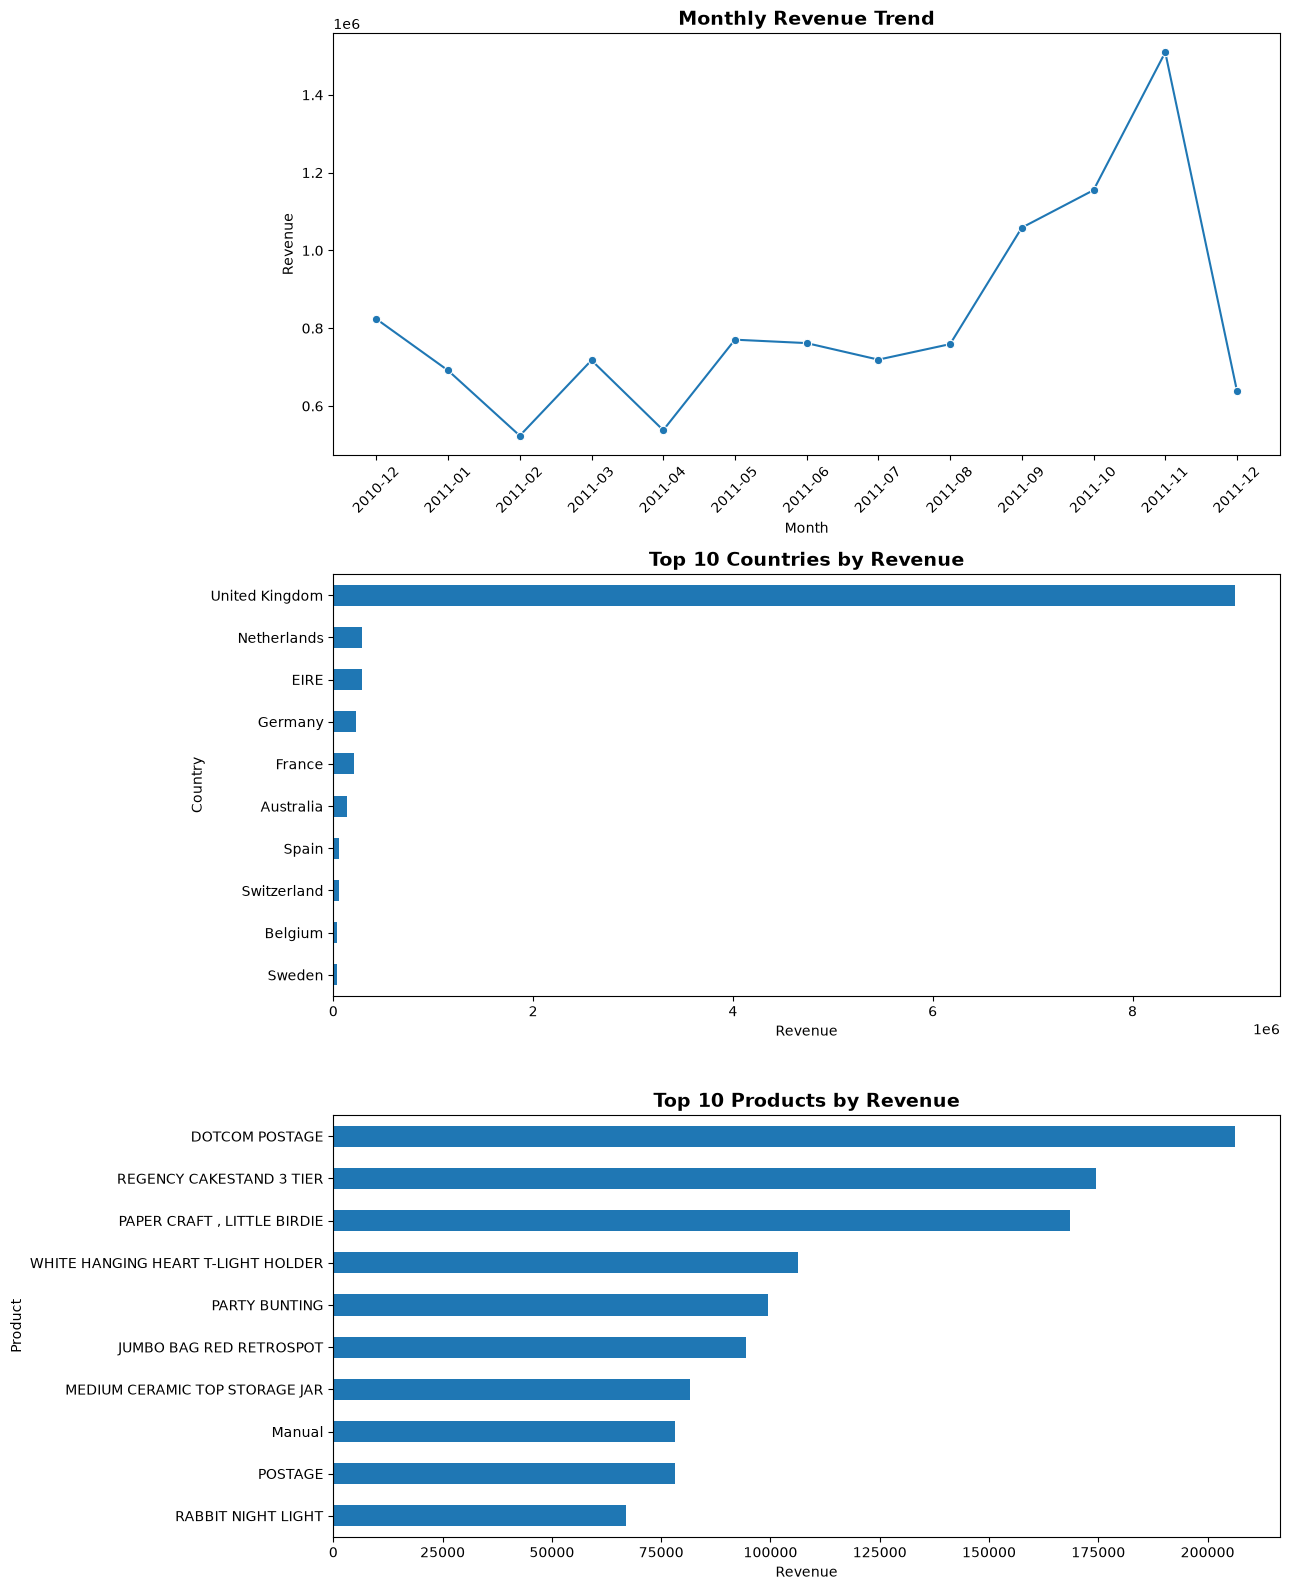

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

sales = df.loc[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

monthly = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

monthly["Month"] = monthly["InvoiceDate"].astype(str)

top_countries = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

top_products = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

fig, axes = plt.subplots(3, 1, figsize=(13, 16))

sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o", ax=axes[0])
axes[0].set_title("Monthly Revenue Trend", fontsize=14, weight="bold")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=45)

top_countries.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Countries by Revenue", fontsize=14, weight="bold")
axes[1].set_xlabel("Revenue")
axes[1].set_ylabel("Country")

top_products.plot(kind="barh", ax=axes[2])
axes[2].set_title("Top 10 Products by Revenue", fontsize=14, weight="bold")
axes[2].set_xlabel("Revenue")
axes[2].set_ylabel("Product")

plt.tight_layout()
plt.show()


### 7.1 Interpretation of Exploratory Findings

The preliminary analysis reveals a strong concentration of revenue in the United Kingdom, which substantially exceeds the contribution of other countries.

Monthly revenue increased considerably during the final months of the observation period, reaching its highest level in November 2011. This pattern may reflect seasonal purchasing behaviour.

The product analysis also identifies several high-revenue descriptions. However, certain entries represent delivery or administrative charges rather than physical merchandise.

These findings are preliminary because exact duplicate records and other transaction anomalies have not yet been addressed. December 2011 is also an incomplete observation period.


## 8. Customer Behaviour Analysis

This section examines customer purchasing patterns using identified customer records. The analysis focuses on purchase frequency, total spending and monthly customer activity to understand behavioural differences within the retail customer base.

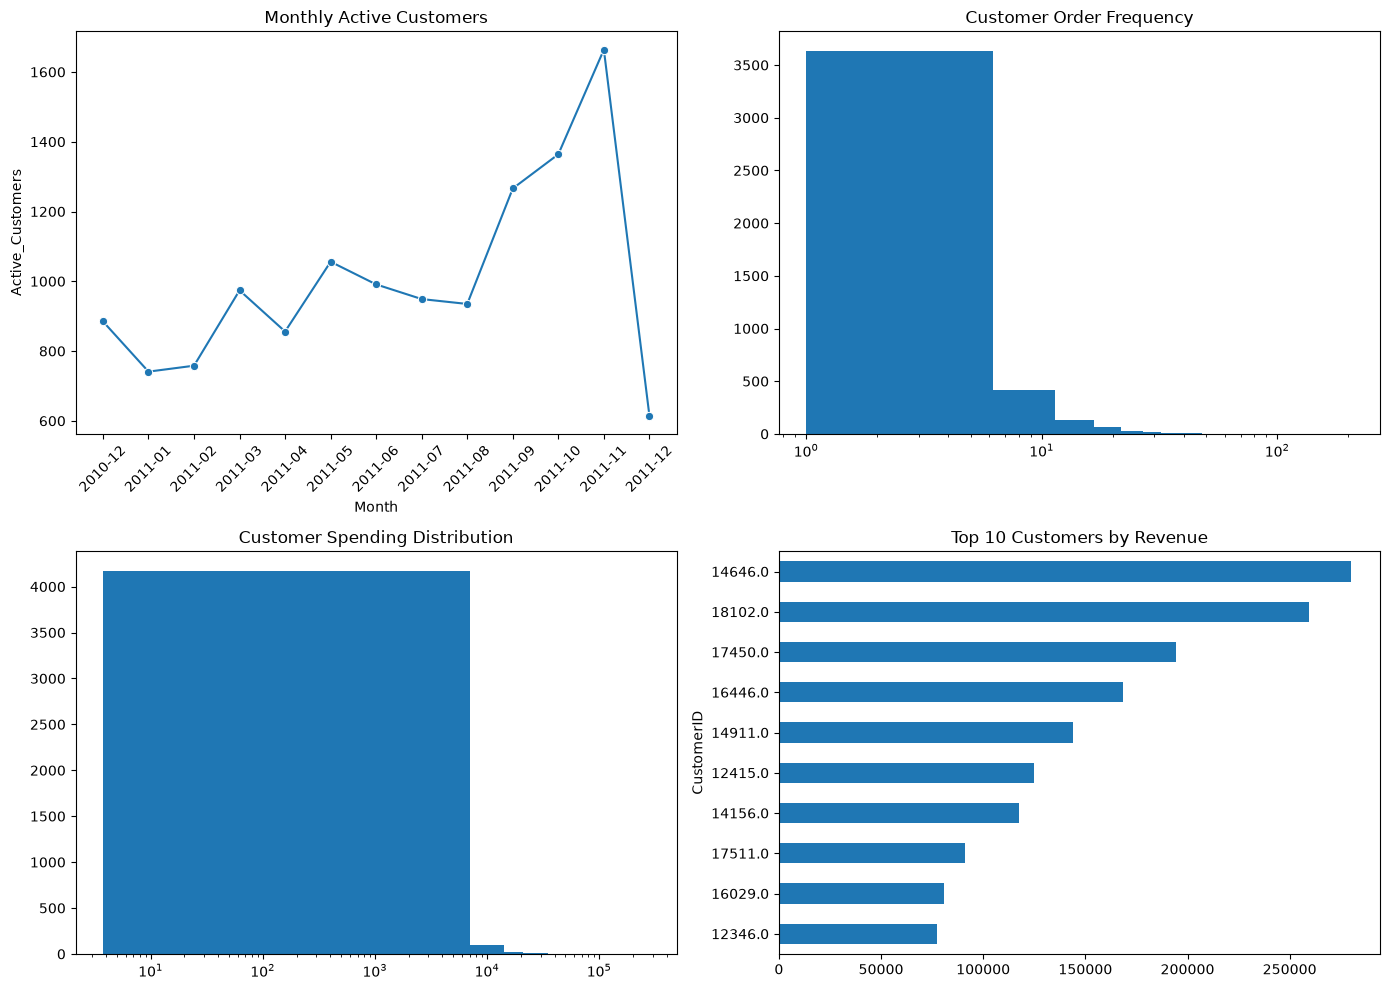

Identified customers: 4338


,count,mean,min,25%,50%,75%,max,std
Total_Revenue,"4,338.00","2,054.27",3.75,307.41,674.49,"1,661.74","280,206.02","8,989.23"
Total_Orders,"4,338.00",4.27,1.00,1.00,2.00,5.00,209.00,7.70
Total_Quantity,"4,338.00","1,191.29",1.00,160.00,379.00,992.75,"196,915.00","5,046.08"
First_Purchase,4338,2011-04-30 17:06:50.857538,2010-12-01 08:26:00,2011-01-17 11:13:15,2011-04-05 09:52:30,2011-08-19 10:11:30,2011-12-09 12:16:00,NaN
Last_Purchase,4338,2011-09-08 11:38:59.045643,2010-12-01 09:53:00,2011-07-20 19:18:00,2011-10-20 10:40:30,2011-11-22 11:05:45,2011-12-09 12:50:00,NaN


In [40]:
sales = df.loc[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

identified_sales = sales.dropna(subset=["CustomerID"]).copy()

customer_summary = (
    identified_sales.groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
)

monthly_activity = (
    identified_sales.groupby(
        identified_sales["InvoiceDate"].dt.to_period("M")
    )
    .agg(
        Active_Customers=("CustomerID", "nunique"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

monthly_activity["Month"] = monthly_activity["InvoiceDate"].astype(str)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.lineplot(data=monthly_activity, x="Month", y="Active_Customers", marker="o", ax=axes[0, 0])
axes[0, 0].set_title("Monthly Active Customers")
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].hist(customer_summary["Total_Orders"], bins=40)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Customer Order Frequency")

axes[1, 0].hist(customer_summary["Total_Revenue"], bins=40)
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("Customer Spending Distribution")

customer_summary.nlargest(10, "Total_Revenue")["Total_Revenue"].sort_values().plot(
    kind="barh", ax=axes[1, 1]
)
axes[1, 1].set_title("Top 10 Customers by Revenue")

plt.tight_layout()
plt.show()

print("Identified customers:", len(customer_summary))
display(customer_summary.describe().T)

## 9. Data Cleaning and Preprocessing

The preprocessing is to stage addresses duplicate records, incomplete customer identifiers, cancelled transactions, returns and invalid prices.

The original dataset is preserved. and  a separate dataset is constructed for customer-level analysis using valid purchase transactions.

In [41]:
df_unique = df.drop_duplicates().copy()

invoice_no = df_unique["InvoiceNo"].astype("string").str.strip()

purchase_mask = (
    (df_unique["Quantity"] > 0) &
    (df_unique["UnitPrice"] > 0) &
    (~invoice_no.str.startswith("C", na=False))
)

valid_sales = df_unique.loc[purchase_mask].copy()

customer_sales = valid_sales.dropna(subset=["CustomerID"]).copy()

customer_sales["CustomerID"] = (
    customer_sales["CustomerID"].astype("int64")
)

customer_sales["Revenue"] = (
    customer_sales["Quantity"] * customer_sales["UnitPrice"]
)

cleaning_summary = pd.Series({
    "Original records": len(df),
    "Exact duplicates removed": len(df) - len(df_unique),
    "Records after deduplication": len(df_unique),
    "Valid purchase transactions": len(valid_sales),
    "Purchases without CustomerID": valid_sales["CustomerID"].isna().sum(),
    "Customer-level transaction records": len(customer_sales),
    "Unique identified customers": customer_sales["CustomerID"].nunique()
})

display(cleaning_summary.to_frame("Value"))

,Value
Original records,541909
Exact duplicates removed,5268
Records after deduplication,536641
Valid purchase transactions,524878
Purchases without CustomerID,132186
Customer-level transaction records,392692
Unique identified customers,4338


## 10. RFM Feature Engineering and Churn Definition

Customer-level features are constructed using Recency, Frequency and Monetary (RFM) analysis.

The observation period ends on August 31, 2011. Customer behaviour is measured using transactions recorded up to this date.

The subsequent 90-day period, from September 1 to November 29, 2011, is used to determine customer inactivity.

Customers with no qualifying purchase during the prediction period are assigned a churn label of 1, while customers who make at least one qualifying purchase are assigned a label of 0.

The churn label represents observed purchase inactivity rather than confirmed permanent customer loss.

In [42]:
observation_end = pd.Timestamp("2011-08-31 23:59:59")
prediction_start = pd.Timestamp("2011-09-01 00:00:00")
prediction_end = pd.Timestamp("2011-11-29 23:59:59")

analysis_data = df.drop_duplicates().copy()

analysis_data["InvoiceDate"] = pd.to_datetime(
    analysis_data["InvoiceDate"],
    errors="coerce"
)

analysis_data["CustomerID"] = pd.to_numeric(
    analysis_data["CustomerID"],
    errors="coerce"
)

invoice_text = analysis_data["InvoiceNo"].astype("string").str.strip()

purchase_mask = (
    (analysis_data["Quantity"] > 0) &
    (analysis_data["UnitPrice"] > 0) &
    (~invoice_text.str.startswith("C", na=False)) &
    analysis_data["CustomerID"].notna() &
    analysis_data["InvoiceDate"].notna()
)

purchases = analysis_data.loc[purchase_mask].copy()

purchases["InvoiceNo"] = invoice_text.loc[purchases.index].astype(str)
purchases["CustomerID"] = purchases["CustomerID"].astype("int64")
purchases["Revenue"] = purchases["Quantity"] * purchases["UnitPrice"]

historical_data = purchases.loc[
    purchases["InvoiceDate"] <= observation_end
].copy()

future_data = purchases.loc[
    (purchases["InvoiceDate"] >= prediction_start) &
    (purchases["InvoiceDate"] <= prediction_end)
].copy()

rfm = historical_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (observation_end - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max")
)

future_customers = future_data["CustomerID"].unique()

rfm["Churn"] = (~rfm.index.isin(future_customers)).astype(int)

rfm["Average_Order_Value"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

print("RFM dataset successfully created.")
print("Historical customers:", len(rfm))
print("Inactive customers:", (rfm["Churn"] == 1).sum())
print("Retained customers:", (rfm["Churn"] == 0).sum())
print("Inactivity rate:", f"{rfm['Churn'].mean():.2%}")

print("\nRFM sample:")
display(rfm.head(10))

print("\nRFM statistical summary:")
display(rfm.describe().T)

RFM dataset successfully created.
Historical customers: 3317
Inactive customers: 1453
Retained customers: 1864
Inactivity rate: 43.80%

RFM sample:


,Recency,Frequency,Monetary,Total_Quantity,First_Purchase,Last_Purchase,Churn,Average_Order_Value
CustomerID,,,,,,,,
12346,225,1,"77,183.60",74215,2011-01-18 10:01:00,2011-01-18 10:01:00,1,"77,183.60"
12347,29,5,"2,790.86",1590,2010-12-07 14:57:00,2011-08-02 08:48:00,0,558.17
12348,148,3,"1,487.24",2124,2010-12-16 19:09:00,2011-04-05 10:47:00,0,495.75
12350,210,1,334.40,197,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40
12352,162,5,"1,561.81",254,2011-02-16 12:33:00,2011-03-22 16:08:00,0,312.36
12353,104,1,89.00,20,2011-05-19 17:47:00,2011-05-19 17:47:00,1,89.00
12354,132,1,"1,079.40",530,2011-04-21 13:11:00,2011-04-21 13:11:00,1,"1,079.40"
12355,114,1,459.40,240,2011-05-09 13:49:00,2011-05-09 13:49:00,1,459.40
12356,145,2,"2,753.08",1586,2011-01-18 09:50:00,2011-04-08 12:33:00,0,"1,376.54"



RFM statistical summary:


,count,mean,min,25%,50%,75%,max,std
Recency,"3,317.00",92.14,0.00,27.00,72.00,146.00,273.00,76.69
Frequency,"3,317.00",3.44,1.00,1.00,2.00,4.00,127.00,5.59
Monetary,"3,317.00","1,575.97",2.90,258.25,552.80,"1,355.11","176,355.94","5,974.01"
Total_Quantity,"3,317.00",923.76,1.00,128.00,305.00,767.00,"126,731.00","3,733.91"
First_Purchase,3317,2011-03-08 19:06:06.891769,2010-12-01 08:26:00,2010-12-17 14:15:00,2011-02-28 09:26:00,2011-05-06 13:01:00,2011-08-31 17:12:00,NaN
Last_Purchase,3317,2011-05-31 09:35:22.447995,2010-12-01 09:53:00,2011-04-07 19:16:00,2011-06-20 10:13:00,2011-08-04 15:23:00,2011-08-31 17:16:00,NaN
Churn,"3,317.00",0.44,0.00,0.00,0.00,1.00,1.00,0.50
Average_Order_Value,"3,317.00",399.43,2.90,168.20,283.50,412.65,"77,183.60","1,435.70"


## 11. Customer Churn Distribution

This section examines the distribution of the target variable to determine the proportion of customers classified as inactive or retained during the 90-day prediction period.

The resulting class distribution will guide the selection of appropriate model evaluation metrics and class imbalance handling techniques.

,Customers,Percentage
Retained,1864,56.20
Inactive,1453,43.80


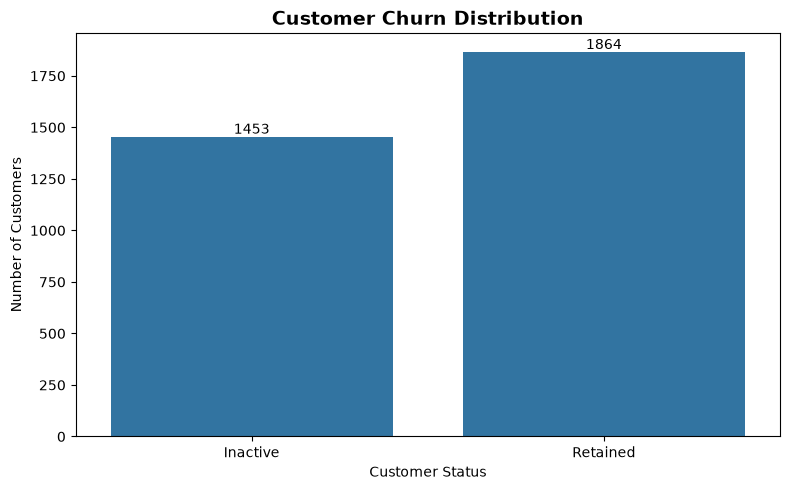

In [43]:
churn_counts = rfm["Churn"].value_counts().reindex([0, 1], fill_value=0)

churn_summary = pd.DataFrame({
    "Customers": churn_counts,
    "Percentage": (churn_counts / len(rfm) * 100).round(2)
})

churn_summary.index = ["Retained", "Inactive"]

display(churn_summary)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=rfm["Churn"].map({0: "Retained", 1: "Inactive"})
)

ax.set_title("Customer Churn Distribution", fontsize=14, weight="bold")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### 11.1 Interpretation of Churn Distribution

The dataset contains 3,317 identified customers, of whom 1,453 (43.8%) were classified as inactive and 1,864 (56.2%) as retained during the prediction period.

The difference between the two classes indicates a moderate imbalance. This distribution should be considered during model development, particularly when selecting evaluation metrics and classification thresholds.

Accuracy alone will not be sufficient to assess model performance. Precision, recall, F1-score and PR-AUC will also be considered.

In [44]:
model_df = rfm.copy()

model_df["Customer_Tenure_Days"] = (
    observation_end - model_df["First_Purchase"]
).dt.days

model_df["Purchase_Activity_Span_Days"] = (
    model_df["Last_Purchase"] - model_df["First_Purchase"]
).dt.days

model_df["Average_Order_Value"] = (
    model_df["Monetary"] / model_df["Frequency"]
)

model_df["Average_Quantity_Per_Order"] = (
    model_df["Total_Quantity"] / model_df["Frequency"]
)

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Customer_Tenure_Days",
    "Purchase_Activity_Span_Days",
    "Average_Order_Value",
    "Average_Quantity_Per_Order"
]

model_df = model_df.replace([np.inf, -np.inf], np.nan)

print("Predictive dataset shape:", model_df.shape)

print("\nMissing values:")
display(model_df[feature_columns + ["Churn"]].isnull().sum())

print("\nFeature summary:")
display(model_df[feature_columns].describe().T)

Predictive dataset shape: (3317, 11)

Missing values:


Recency                        0
Frequency                      0
Monetary                       0
Total_Quantity                 0
Customer_Tenure_Days           0
Purchase_Activity_Span_Days    0
Average_Order_Value            0
Average_Quantity_Per_Order     0
Churn                          0
dtype: int64


Feature summary:


,count,mean,std,min,25%,50%,75%,max
Recency,"3,317.00",92.14,76.69,0.00,27.00,72.00,146.00,273.00
Frequency,"3,317.00",3.44,5.59,1.00,1.00,2.00,4.00,127.00
Monetary,"3,317.00","1,575.97","5,974.01",2.90,258.25,552.80,"1,355.11","176,355.94"
Total_Quantity,"3,317.00",923.76,"3,733.91",1.00,128.00,305.00,767.00,"126,731.00"
Customer_Tenure_Days,"3,317.00",175.75,77.86,0.00,117.00,184.00,257.00,273.00
Purchase_Activity_Span_Days,"3,317.00",83.32,91.78,0.00,0.00,48.00,162.00,272.00
Average_Order_Value,"3,317.00",399.43,"1,435.70",2.90,168.20,283.50,412.65,"77,183.60"
Average_Quantity_Per_Order,"3,317.00",241.92,"1,321.09",1.00,83.00,147.67,256.00,"74,215.00"


## 12. Feature Distribution and Correlation Analysis

This section evaluates the distribution of customer-level predictive features and examines their relationships with one another and the target variable.

The analysis helps identify skewed distributions, potential redundancy and associations that may influence model interpretation.

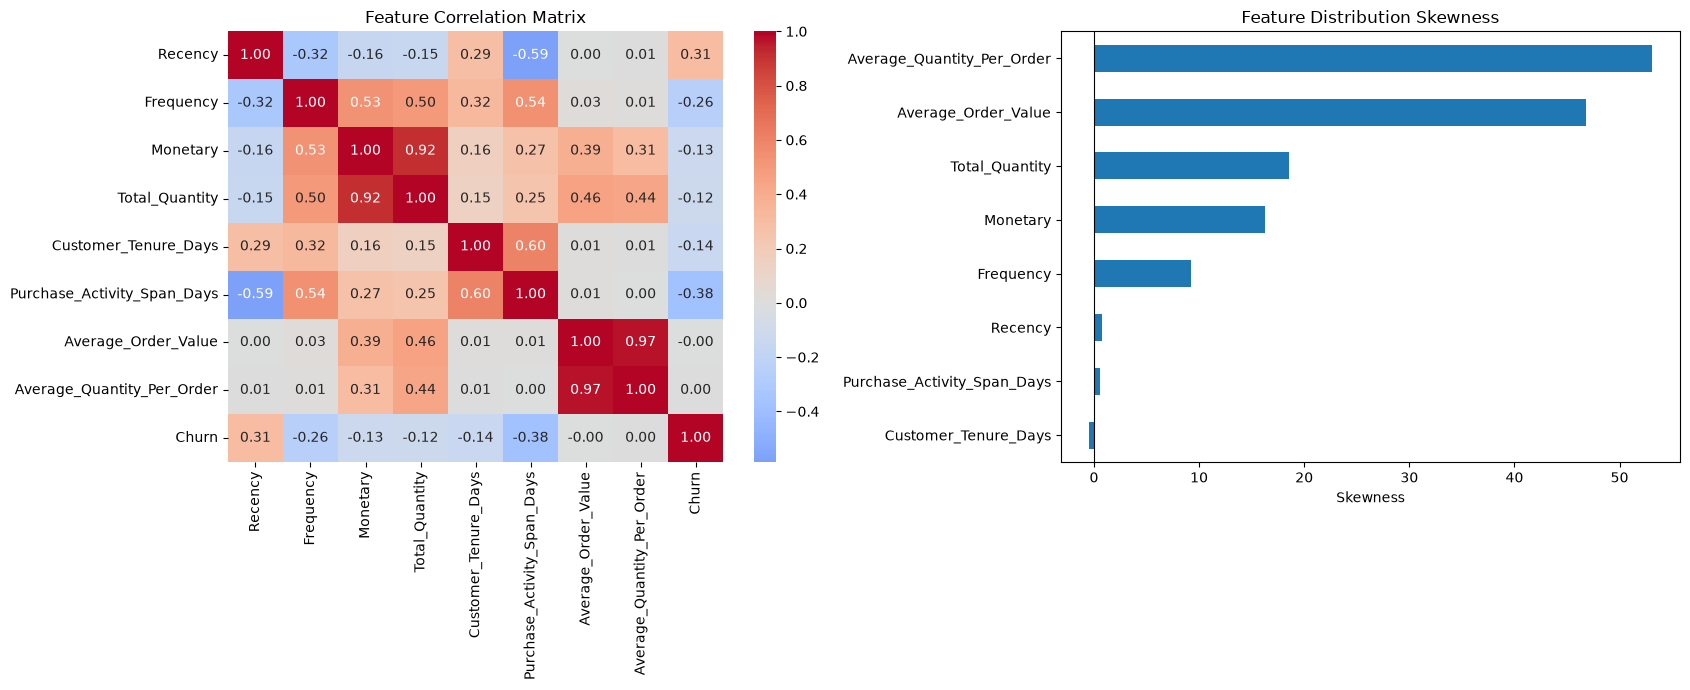

,Skewness
Average_Quantity_Per_Order,53.07
Average_Order_Value,46.83
Total_Quantity,18.58
Monetary,16.27
Frequency,9.19
Recency,0.78
Purchase_Activity_Span_Days,0.61
Customer_Tenure_Days,-0.48


In [45]:
feature_corr = model_df[feature_columns + ["Churn"]].corr()

skewness = (
    model_df[feature_columns]
    .skew()
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)

axes[0].set_title("Feature Correlation Matrix")

skewness.sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Feature Distribution Skewness")
axes[1].set_xlabel("Skewness")

plt.tight_layout()
plt.show()

display(skewness.to_frame("Skewness"))

## 13. Preparation of Training and Testing Data

The predictive dataset is divided into training and testing subsets using stratified sampling.

Stratification preserves the original proportion of inactive and retained customers in both subsets.

The testing subset is kept separate and will only be used for final model evaluation.

In [46]:
from sklearn.model_selection import train_test_split

X = model_df[feature_columns].copy()
y = model_df["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

split_summary = pd.DataFrame({
    "Training Set": [
        len(X_train),
        (y_train == 0).sum(),
        (y_train == 1).sum()
    ],
    "Testing Set": [
        len(X_test),
        (y_test == 0).sum(),
        (y_test == 1).sum()
    ]
}, index=["Total Customers", "Retained", "Inactive"])

display(split_summary)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training inactivity rate:", f"{y_train.mean():.2%}")
print("Testing inactivity rate:", f"{y_test.mean():.2%}")

,Training Set,Testing Set
Total Customers,2653,664
Retained,1491,373
Inactive,1162,291


Training shape: (2653, 8)
Testing shape: (664, 8)
Training inactivity rate: 43.80%
Testing inactivity rate: 43.83%


## 14. Baseline Model Evaluation

A baseline classifier is established to provide a reference point for evaluating more advanced machine learning algorithms.

The majority-class strategy predicts every customer as retained. Its performance demonstrates the limitations of relying exclusively on accuracy when the objective is to identify inactive customers.

The positive class is defined as customer inactivity (Churn = 1).

In [47]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

baseline = DummyClassifier(strategy="prior")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

baseline_results = pd.DataFrame([{
    "Model": "Majority Class Baseline",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, baseline_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_probabilities),
    "PR-AUC": average_precision_score(y_test, baseline_probabilities)
}])

display(baseline_results.round(4))

print("Confusion Matrix:")
display(confusion_matrix(y_test, baseline_predictions))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Majority Class Baseline,0.56,0.00,0.00,0.00,0.50,0.44


Confusion Matrix:


array([[373,   0],
       [291,   0]])

## 15. Machine Learning Model Development

Two ensemble learning algorithms, Random Forest and XGBoost, are developed to predict customer inactivity.

Their initial performance is evaluated using a validation subset obtained from the training data. A majority-class baseline is included for comparison.

The original test set is reserved for final model evaluation.

In [48]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training records:", len(X_fit))
print("Validation records:", len(X_val))
print("Final test records:", len(X_test))

Model training records: 2122
Validation records: 531
Final test records: 664


In [49]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier

models = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_fit, y_fit)

print("All models trained successfully.")

All models trained successfully.


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

results = []
confusion_matrices = {}

for name, model in models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

    confusion_matrices[name] = confusion_matrix(y_val, predictions)

model_results = pd.DataFrame(results).set_index("Model")

display(model_results.round(4))

for name, matrix in confusion_matrices.items():
    print(f"\n{name}")
    display(pd.DataFrame(
        matrix,
        index=["Actual Retained", "Actual Inactive"],
        columns=["Predicted Retained", "Predicted Inactive"]
    ))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Baseline,0.56,0.00,0.00,0.00,0.50,0.44
Random Forest,0.66,0.61,0.63,0.62,0.72,0.60
XGBoost,0.66,0.61,0.65,0.63,0.74,0.63



Baseline


,Predicted Retained,Predicted Inactive
Actual Retained,298,0
Actual Inactive,233,0



Random Forest


,Predicted Retained,Predicted Inactive
Actual Retained,205,93
Actual Inactive,86,147



XGBoost


,Predicted Retained,Predicted Inactive
Actual Retained,202,96
Actual Inactive,82,151


## 16. Class Imbalance Handling

Class weighting is investigated to determine whether assigning greater importance to inactive customers improves predictive performance.

Random Forest class weighting and XGBoost positive-class weighting are evaluated independently.

All experiments use the training subset, while model selection is performed using the validation subset. The final test set remains untouched.

In [51]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_pos_weight = negative_count / positive_count

weighted_models = {
    "Random Forest Balanced": RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost Weighted": XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

for name, model in weighted_models.items():
    model.fit(X_fit, y_fit)

print("Weighted models trained successfully.")
print("Positive class weight:", round(scale_pos_weight, 3))

Weighted models trained successfully.
Positive class weight: 1.284


In [52]:
all_models = {
    "Random Forest": models["Random Forest"],
    "XGBoost": models["XGBoost"],
    **weighted_models
}

comparison = []

for name, model in all_models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

weighted_results = pd.DataFrame(comparison).set_index("Model")

display(weighted_results.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.66,0.61,0.63,0.62,0.72,0.60
XGBoost,0.66,0.61,0.65,0.63,0.74,0.63
Random Forest Balanced,0.66,0.59,0.69,0.64,0.72,0.60
XGBoost Weighted,0.68,0.61,0.73,0.67,0.74,0.63


### 16.1 Comparison of Class Imbalance Strategies

Class weighting improved the performance of both ensemble classifiers in terms of identifying inactive customers.

The weighted XGBoost model achieved the highest recall of 0.73 and an F1-score of 0.67, compared with a recall of 0.65 and an F1-score of 0.63 for the original XGBoost model.

The results suggest that assigning greater importance to the inactive customer class improves the model's ability to detect potential churn.

Weighted XGBoost is therefore selected as the leading candidate for further threshold optimization. However, final model selection will also consider precision, ROC-AUC, PR-AUC and business implications.

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

best_candidate = weighted_models["XGBoost Weighted"]

val_probabilities = best_candidate.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.25, 0.76, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "False Positives": fp,
        "False Negatives": fn,
        "Flagged Customers": tp + fp
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(3))

,Threshold,Accuracy,Precision,Recall,F1-Score,Balanced Accuracy,False Positives,False Negatives,Flagged Customers
0,0.25,0.62,0.54,0.92,0.68,0.65,185,19,399
1,0.30,0.64,0.56,0.91,0.69,0.67,169,21,381
2,0.35,0.65,0.57,0.88,0.69,0.68,155,29,359
3,0.40,0.66,0.58,0.84,0.69,0.68,141,38,336
4,0.45,0.69,0.61,0.81,0.69,0.70,123,44,312
5,0.50,0.68,0.61,0.73,0.67,0.68,110,62,281
6,0.55,0.66,0.60,0.64,0.62,0.66,99,83,249
7,0.60,0.66,0.63,0.57,0.60,0.65,80,99,214
8,0.65,0.66,0.65,0.48,0.55,0.64,60,122,171
9,0.70,0.64,0.65,0.38,0.48,0.61,47,144,136


### 16.2 Classification Threshold Optimization

The classification threshold was evaluated using validation data to identify an appropriate balance between precision and recall.

A threshold of 0.45 was selected for the weighted XGBoost model because it achieved the highest balanced accuracy among the tested thresholds, while maintaining a strong F1-score.

At this threshold, the model identified 81% of inactive customers, with a precision of approximately 61%.

The selected threshold will be kept fixed during final evaluation on the independent test dataset. The test data will not be used for further model or threshold selection.

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Weighted XGBoost,0.45,0.64,0.57,0.74,0.64,0.71,0.59


Classification Report:
              precision    recall  f1-score   support

    Retained       0.73      0.57      0.64       373
    Inactive       0.57      0.74      0.64       291

    accuracy                           0.64       664
   macro avg       0.65      0.65      0.64       664
weighted avg       0.66      0.64      0.64       664



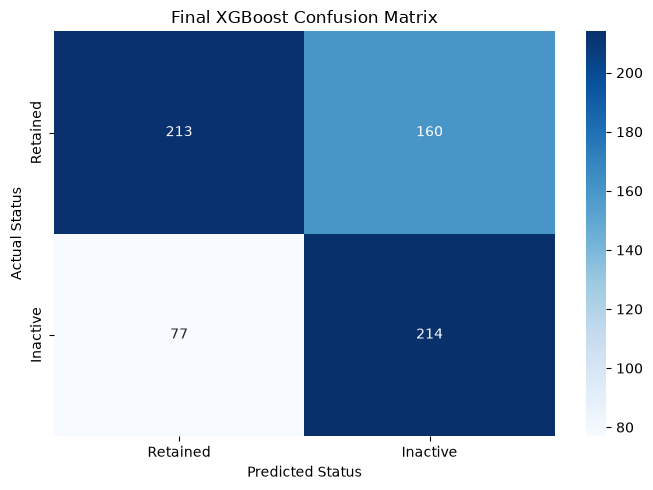

In [54]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

selected_threshold = 0.45

final_scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

final_model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=final_scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

final_metrics = pd.DataFrame([{
    "Model": "Weighted XGBoost",
    "Threshold": selected_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "F1-Score": f1_score(y_test, test_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities)
}])

display(final_metrics.round(4))

print("Classification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Retained", "Inactive"]
))

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Retained", "Inactive"],
    yticklabels=["Retained", "Inactive"]
)

plt.title("Final XGBoost Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.show()

## 17. Model Explainability Using SHAP

SHAP (SHapley Additive exPlanations) is used to interpret the predictions generated by the final XGBoost model.

The analysis examines the relative contribution of customer behavioural features to model predictions and identifies the features that have the greatest influence on inactivity classification.

These explanations describe model behaviour and should not be interpreted as evidence of causation.

,Feature,Mean_Absolute_SHAP
1,Frequency,0.36
5,Purchase_Activity_Span_Days,0.34
0,Recency,0.30
3,Total_Quantity,0.28
6,Average_Order_Value,0.20
2,Monetary,0.17
7,Average_Quantity_Per_Order,0.15
4,Customer_Tenure_Days,0.13


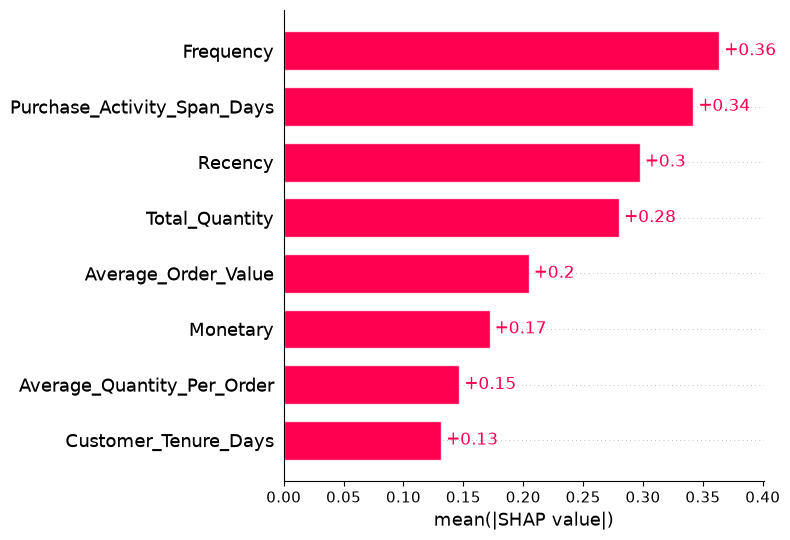

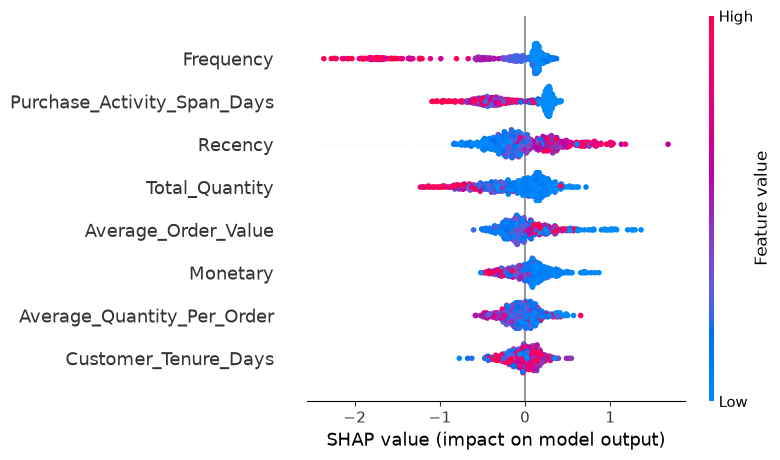

In [55]:
import shap

explainer = shap.TreeExplainer(final_model)

shap_values = explainer(X_test)

shap_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

display(shap_importance)

plt.figure()
shap.plots.bar(shap_values, max_display=8, show=False)
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.beeswarm(shap_values, max_display=8, show=False)
plt.tight_layout()
plt.show()

In [56]:
display(final_metrics.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Weighted XGBoost,0.45,0.64,0.57,0.74,0.64,0.71,0.59



## 17. Final Model Evaluation

The weighted XGBoost classifier was evaluated on an independent test set containing 664 customers. The classification threshold of 0.45 was selected previously using validation data and was kept fixed during final evaluation.

The model achieved an accuracy of 64.31%, precision of 57.22%, recall of 73.54%, and F1-score of 64.36%. Its ROC-AUC and PR-AUC were 0.71 and 0.59, respectively.

The model correctly identified 214 of the 291 inactive customers, while incorrectly classifying 160 retained customers as inactive.

These findings demonstrate that the model can identify a substantial proportion of inactive customers, although false positive predictions remain an important consideration when designing retention interventions.


## 18. Model Explainability Using SHAP

SHAP (SHapley Additive exPlanations) is used to interpret the predictions generated by the final XGBoost model.

The analysis identifies the relative contribution of customer behavioural features to individual predictions and evaluates their overall influence on model output.

The results provide insight into the behavioural patterns learned by the model. SHAP contributions describe model behaviour and do not establish causal relationships.

,Feature,Mean_Absolute_SHAP
1,Frequency,0.36
5,Purchase_Activity_Span_Days,0.34
0,Recency,0.30
3,Total_Quantity,0.28
6,Average_Order_Value,0.20
2,Monetary,0.17
7,Average_Quantity_Per_Order,0.15
4,Customer_Tenure_Days,0.13


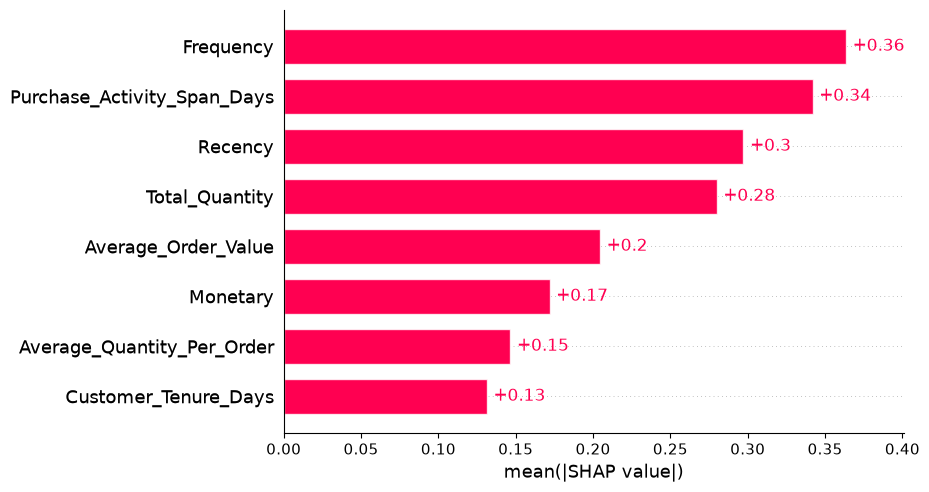

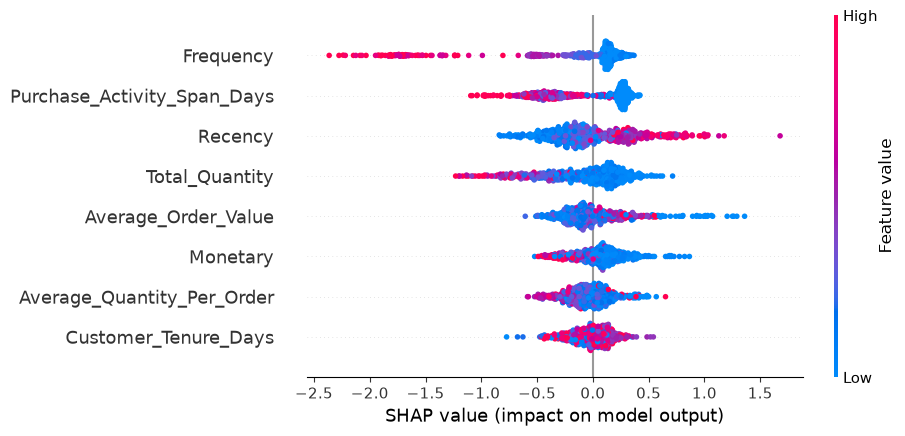

In [57]:
import shap

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_test)

values = shap_values.values

if values.ndim == 3:
    values = values[:, :, 1]

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

display(shap_importance)

shap.plots.bar(shap_values, max_display=8)

shap.plots.beeswarm(shap_values, max_display=8)

## 19. Customer Risk Segmentation

The predicted inactivity scores generated by the final XGBoost classifier are used to categorize customers into three risk tiers: high, medium and low.

The segmentation provides a practical framework for prioritizing retention activities according to predicted customer inactivity risk.

The risk categories are based on predefined score thresholds and are intended for operational prioritization rather than representing calibrated probabilities.

,Customers,Average_Score,Actual_Inactivity_Rate,Actual_Inactive_Customers
Risk_Tier,,,,
High,261,0.73,0.59,155
Medium,113,0.53,0.52,59
Low,290,0.21,0.27,77


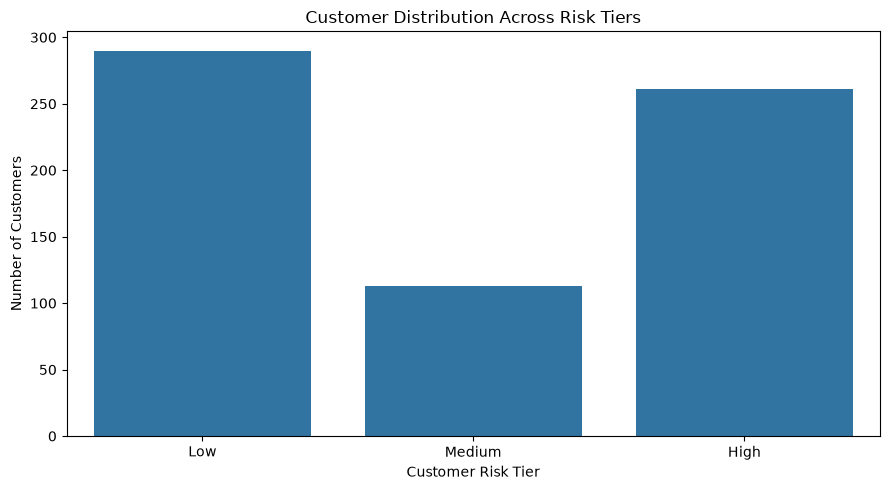

In [60]:
risk_segments = pd.DataFrame(index=X_test.index)

risk_segments.index.name = "CustomerID"
risk_segments["Churn_Score"] = test_probabilities
risk_segments["Predicted_Churn"] = test_predictions
risk_segments["Actual_Churn"] = y_test

risk_segments["Risk_Tier"] = pd.cut(
    risk_segments["Churn_Score"],
    bins=[-np.inf, 0.45, 0.60, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

risk_summary = (
    risk_segments.groupby("Risk_Tier", observed=False)
    .agg(
        Customers=("Churn_Score", "size"),
        Average_Score=("Churn_Score", "mean"),
        Actual_Inactivity_Rate=("Actual_Churn", "mean"),
        Actual_Inactive_Customers=("Actual_Churn", "sum")
    )
    .reindex(["High", "Medium", "Low"])
)

display(risk_summary.round(3))

plt.figure(figsize=(9, 5))

sns.countplot(
    data=risk_segments.reset_index(),
    x="Risk_Tier",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Distribution Across Risk Tiers")
plt.xlabel("Customer Risk Tier")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [62]:
from pathlib import Path

current_dir = Path.cwd()

project_root = next(
    (path for path in [current_dir, *current_dir.parents]
     if (path / "data.csv").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError("Project folder could not be located.")

output_dir = project_root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "customer_risk_segments.csv"

customer_risk_report.to_csv(
    output_path,
    index_label="CustomerID"
)

print("Risk report exported successfully.")
print("Saved to:", output_path)
print("Records exported:", len(customer_risk_report))

Risk report exported successfully.
Saved to: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/outputs/customer_risk_segments.csv
Records exported: 664


## 18. Model Explainability Using SHAP

SHAP (SHapley Additive exPlanations) is used to interpret the predictions generated by the final XGBoost classifier.

The analysis examines the contribution of individual customer behavioural features to model predictions and identifies the features with the greatest overall influence.

The results provide insight into the behavioural patterns learned by the model. SHAP values describe model behaviour and should not be interpreted as evidence of causation.

In [63]:
import shap

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_test)

shap_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance)

,Feature,Mean_Absolute_SHAP
1,Frequency,0.36
5,Purchase_Activity_Span_Days,0.34
0,Recency,0.30
3,Total_Quantity,0.28
6,Average_Order_Value,0.20
2,Monetary,0.17
7,Average_Quantity_Per_Order,0.15
4,Customer_Tenure_Days,0.13


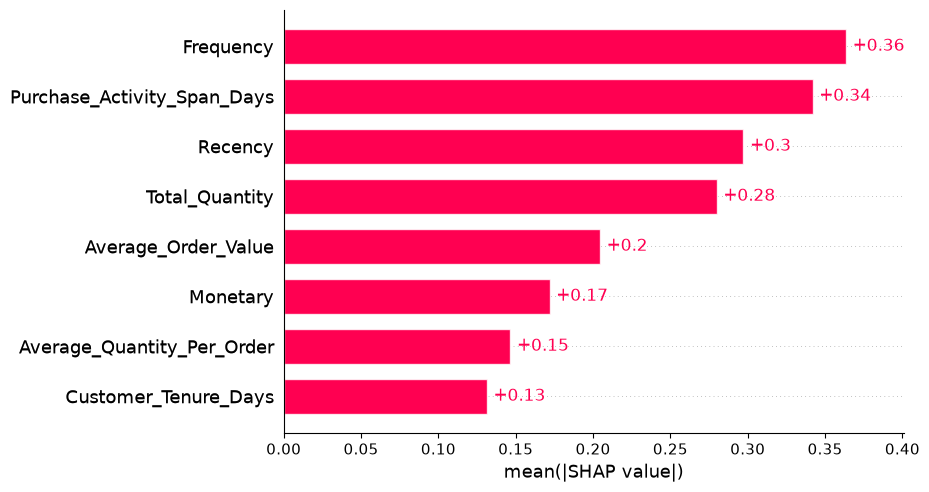

In [64]:
shap.plots.bar(shap_values, max_display=8)

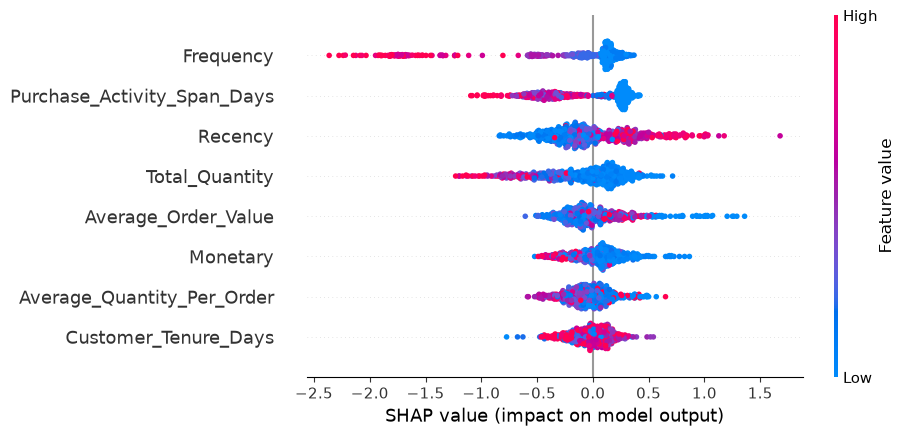

In [65]:
shap.plots.beeswarm(shap_values, max_display=8)

## 19. Customer Risk Segmentation and Business Profiling

Customers are categorized into high, medium and low inactivity-risk groups according to their predicted probabilities.

The segmentation is used to prioritize retention interventions and examine differences in customer purchasing behaviour across risk categories.

In [66]:
from pathlib import Path

risk_segments = pd.DataFrame(index=X_test.index)

risk_segments["Churn_Score"] = test_probabilities
risk_segments["Predicted_Churn"] = (
    test_probabilities >= selected_threshold
).astype(int)
risk_segments["Actual_Churn"] = y_test

risk_segments["Risk_Tier"] = pd.cut(
    risk_segments["Churn_Score"],
    bins=[-np.inf, 0.45, 0.60, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

risk_profile = model_df.loc[
    risk_segments.index,
    feature_columns
].join(risk_segments)

risk_summary = (
    risk_profile.groupby("Risk_Tier", observed=False)
    .agg(
        Customers=("Churn_Score", "size"),
        Average_Risk=("Churn_Score", "mean"),
        Actual_Inactivity=("Actual_Churn", "mean"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .reindex(["High", "Medium", "Low"])
)

display(risk_summary.round(3))

,Customers,Average_Risk,Actual_Inactivity,Average_Recency,Average_Frequency,Average_Monetary
Risk_Tier,,,,,,
High,261,0.73,0.59,144.89,1.34,354.98
Medium,113,0.53,0.52,88.52,1.77,607.76
Low,290,0.21,0.27,48.92,5.89,"3,181.68"


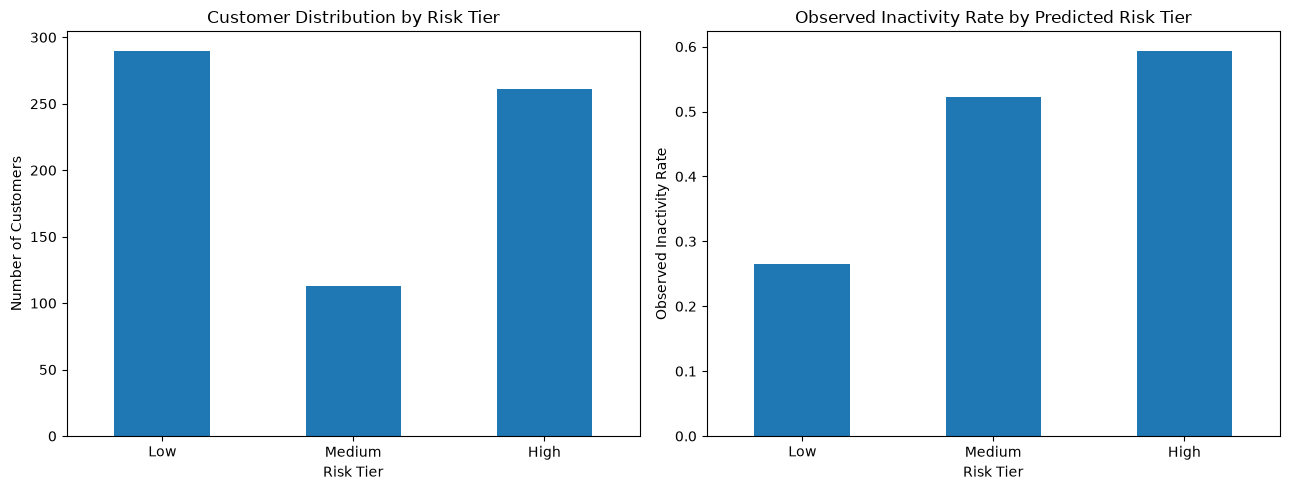

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

risk_counts = (
    risk_profile["Risk_Tier"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

risk_counts.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Risk Tier")
axes[0].set_xlabel("Risk Tier")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)

risk_rates = (
    risk_profile.groupby("Risk_Tier", observed=False)["Actual_Churn"]
    .mean()
    .reindex(["Low", "Medium", "High"])
)

risk_rates.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Observed Inactivity Rate by Predicted Risk Tier")
axes[1].set_xlabel("Risk Tier")
axes[1].set_ylabel("Observed Inactivity Rate")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [68]:
project_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data.csv").exists()
)

output_dir = project_root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

risk_profile.to_csv(
    output_dir / "customer_risk_segments.csv",
    index_label="CustomerID"
)

print("Risk report saved successfully.")
print("Customers:", len(risk_profile))

Risk report saved successfully.
Customers: 664


### 19.1 Interpretation of Customer Risk Segmentation

The customer segmentation analysis reveals meaningful differences in purchasing behaviour across the three predicted risk categories.

High-risk customers represent 261 individuals, with an observed inactivity rate of approximately 59%. Their average purchase recency is higher and their purchasing frequency is lower than those of the other groups.

Medium-risk customers account for 113 individuals, with an observed inactivity rate of approximately 52%.

Low-risk customers account for 290 individuals and exhibit the lowest observed inactivity rate of approximately 27%. They also demonstrate higher historical spending and purchasing frequency.

These findings suggest that model-based segmentation can support differentiated customer retention strategies. However, the observed test-set outcomes are used retrospectively and do not establish the causal effectiveness of retention campaigns.

## 20. Business Impact and Return on Investment Analysis

A scenario-based financial analysis is developed to assess the potential commercial value of model-guided customer retention.

Two campaign strategies are compared: targeting high-risk customers only and targeting both high- and medium-risk customers.

The analysis distinguishes observed customer inactivity from assumed campaign effectiveness. Since the dataset contains no historical retention campaign costs, treatment outcomes or profit margins, financial results are presented as hypothetical scenarios rather than measured business returns.

In [69]:
campaign_strategies = {
    "High Risk Only": ["High"],
    "High and Medium Risk": ["High", "Medium"]
}

campaign_cost_per_customer = 5.0
contribution_per_retained_customer = 100.0

effectiveness_scenarios = [0.05, 0.10, 0.15]

roi_results = []

for strategy, tiers in campaign_strategies.items():

    targeted = risk_profile[
        risk_profile["Risk_Tier"].isin(tiers)
    ]

    customers_targeted = len(targeted)
    observed_inactive = targeted["Actual_Churn"].sum()

    for effectiveness in effectiveness_scenarios:

        expected_retained = observed_inactive * effectiveness

        campaign_cost = (
            customers_targeted * campaign_cost_per_customer
        )

        incremental_contribution = (
            expected_retained * contribution_per_retained_customer
        )

        net_benefit = incremental_contribution - campaign_cost

        roi = (
            net_benefit / campaign_cost * 100
            if campaign_cost > 0 else np.nan
        )

        roi_results.append({
            "Strategy": strategy,
            "Effectiveness": effectiveness,
            "Customers Targeted": customers_targeted,
            "Observed Inactive": observed_inactive,
            "Expected Retained": expected_retained,
            "Campaign Cost": campaign_cost,
            "Incremental Contribution": incremental_contribution,
            "Net Benefit": net_benefit,
            "ROI (%)": roi
        })

roi_scenarios = pd.DataFrame(roi_results)

display(roi_scenarios.round(2))

,Strategy,Effectiveness,Customers Targeted,Observed Inactive,Expected Retained,Campaign Cost,Incremental Contribution,Net Benefit,ROI (%)
0,High Risk Only,0.05,261,155,7.75,"1,305.00",775.00,-530.00,-40.61
1,High Risk Only,0.10,261,155,15.50,"1,305.00","1,550.00",245.00,18.77
2,High Risk Only,0.15,261,155,23.25,"1,305.00","2,325.00","1,020.00",78.16
3,High and Medium Risk,0.05,374,214,10.70,"1,870.00","1,070.00",-800.00,-42.78
4,High and Medium Risk,0.10,374,214,21.40,"1,870.00","2,140.00",270.00,14.44
5,High and Medium Risk,0.15,374,214,32.10,"1,870.00","3,210.00","1,340.00",71.66


## 20.1 Interpretation of Financial Scenarios

The financial analysis compares two customer retention strategies under three hypothetical campaign effectiveness scenarios.

The high-risk-only strategy requires a lower campaign budget and achieves higher percentage ROI across the tested effectiveness scenarios.

The combined high- and medium-risk strategy produces a greater total net benefit when campaign effectiveness reaches 10% and 15%.

The estimated break-even effectiveness is approximately 8.42% for the high-risk-only strategy and 8.74% for the combined strategy.

These figures are illustrative estimates based on assumed campaign costs and incremental contribution per successfully reactivated customer. They do not represent observed campaign outcomes or experimentally established retention effectiveness.

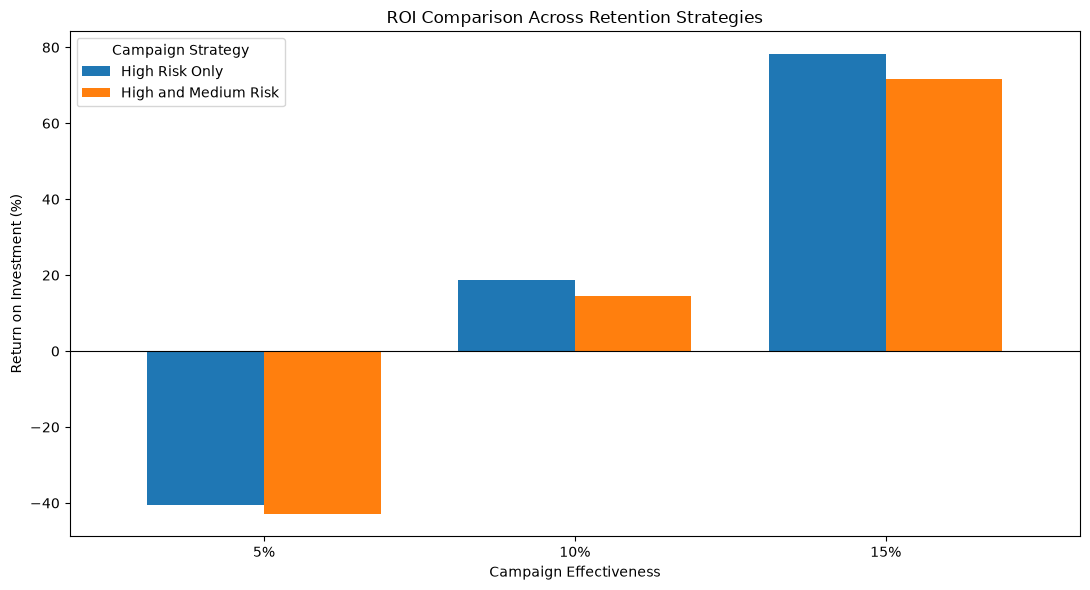

In [70]:
roi_comparison = roi_scenarios.pivot(
    index="Effectiveness",
    columns="Strategy",
    values="ROI (%)"
)

ax = roi_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("ROI Comparison Across Retention Strategies")
ax.set_xlabel("Campaign Effectiveness")
ax.set_ylabel("Return on Investment (%)")
ax.set_xticklabels(["5%", "10%", "15%"], rotation=0)

plt.legend(title="Campaign Strategy")
plt.tight_layout()
plt.show()

In [71]:
break_even = []

for strategy, tiers in campaign_strategies.items():
    targeted = risk_profile[
        risk_profile["Risk_Tier"].isin(tiers)
    ]

    campaign_cost = len(targeted) * campaign_cost_per_customer
    observed_inactive = targeted["Actual_Churn"].sum()

    rate = campaign_cost / (
        observed_inactive * contribution_per_retained_customer
    )

    break_even.append({
        "Strategy": strategy,
        "Break_Even_Effectiveness": rate * 100
    })

display(pd.DataFrame(break_even).round(2))

,Strategy,Break_Even_Effectiveness
0,High Risk Only,8.42
1,High and Medium Risk,8.74


### 20.2 ROI Scenario Analysis

The high-risk-only strategy achieves a higher percentage return on investment across all three campaign effectiveness scenarios.

At 15% effectiveness, this strategy generates an estimated ROI of 78.16%, compared with 71.66% for the combined high- and medium-risk strategy.

However, the combined strategy generates a greater estimated net benefit of 1,340 compared with 1,020 for the high-risk-only strategy.

The results demonstrate a trade-off between investment efficiency and total potential financial benefit.

These estimates are hypothetical and depend on assumed campaign costs, contribution margins and retention effectiveness. Actual campaign experiments would be required to establish realized financial returns.

## 21. SHAP-Based Model Explainability

SHAP is used to interpret the final XGBoost classifier by quantifying the contribution of customer behavioural features to individual predictions.

Global feature importance and feature impact distributions are examined to understand the behavioural patterns associated with predicted customer inactivity.

,Feature,Mean_Absolute_SHAP
1,Frequency,0.36
5,Purchase_Activity_Span_Days,0.34
0,Recency,0.30
3,Total_Quantity,0.28
6,Average_Order_Value,0.20
2,Monetary,0.17
7,Average_Quantity_Per_Order,0.15
4,Customer_Tenure_Days,0.13


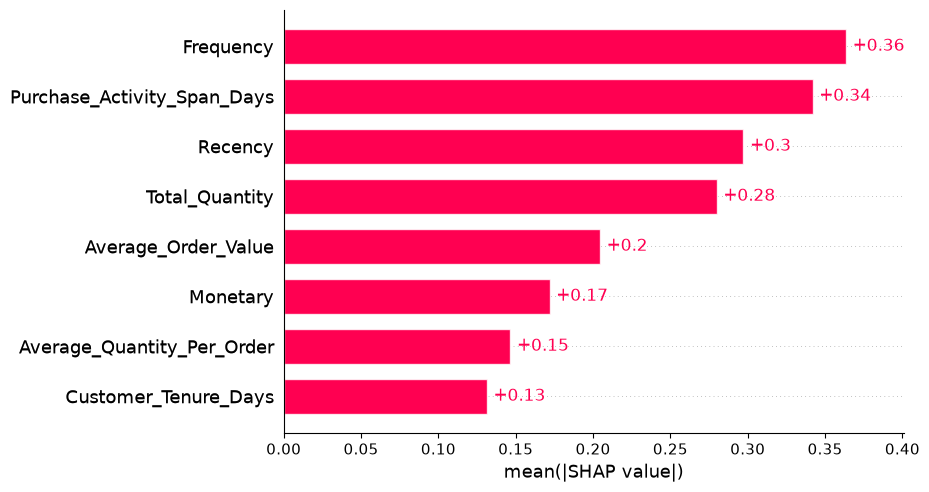

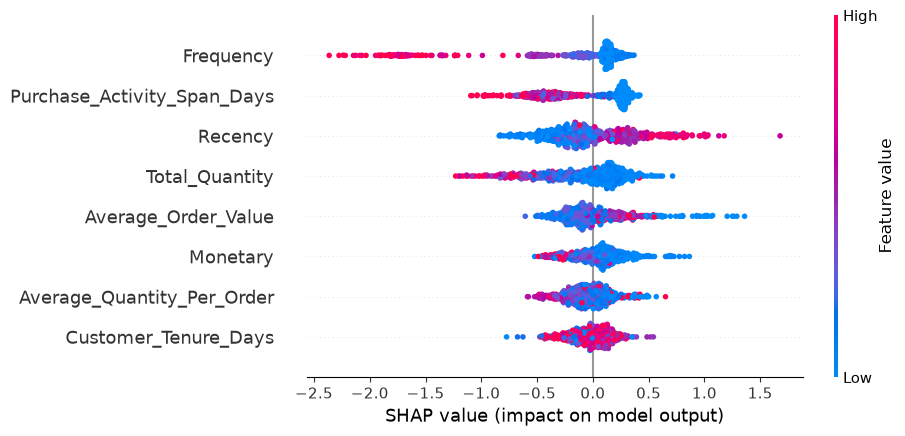

In [72]:
import shap

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_test)

if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

display(shap_importance)

shap.plots.bar(shap_values, max_display=8)
shap.plots.beeswarm(shap_values, max_display=8)


### 21.1 Interpretation of SHAP Results

The SHAP analysis identifies Frequency as the most influential feature, with a mean absolute SHAP value of approximately 0.36, followed by Purchase Activity Span (0.34), Recency (0.30) and Total Quantity (0.28).

The beeswarm visualization indicates that higher purchasing frequency generally contributes to lower predicted inactivity, whereas higher Recency tends to increase the model output associated with inactivity.

Purchase Activity Span also contributes substantially to the model's predictions, demonstrating the relevance of historical customer purchasing patterns.

These findings suggest that purchasing frequency, historical activity and time since the last purchase are particularly informative behavioural indicators.

The results describe the predictive behaviour of the trained model and do not establish causal relationships. Furthermore, correlations among some features may influence how SHAP distributes their individual contributions.


## 22. Feature Redundancy and Model Robustness

A reduced feature configuration is evaluated to investigate the influence of highly correlated customer behavioural variables.

The full feature configuration is compared with a reduced configuration using the same training and validation partitions.

The purpose is to assess whether removing redundant information affects predictive performance and model simplicity.

In [73]:
reduced_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Customer_Tenure_Days",
    "Purchase_Activity_Span_Days",
    "Average_Order_Value"
]

reduced_model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

reduced_model.fit(
    X_fit[reduced_features],
    y_fit
)

reduced_probabilities = reduced_model.predict_proba(
    X_val[reduced_features]
)[:, 1]

reduced_predictions = (
    reduced_probabilities >= 0.45
).astype(int)

reduced_results = pd.DataFrame([
    {
        "Configuration": "Full feature set",
        "Features": len(feature_columns),
        "Accuracy": accuracy_score(
            y_val,
            weighted_models["XGBoost Weighted"].predict(X_val)
        ),
        "Recall": recall_score(
            y_val,
            weighted_models["XGBoost Weighted"].predict(X_val)
        ),
        "F1-Score": f1_score(
            y_val,
            weighted_models["XGBoost Weighted"].predict(X_val)
        ),
        "ROC-AUC": roc_auc_score(
            y_val,
            weighted_models["XGBoost Weighted"].predict_proba(X_val)[:, 1]
        ),
        "PR-AUC": average_precision_score(
            y_val,
            weighted_models["XGBoost Weighted"].predict_proba(X_val)[:, 1]
        )
    },
    {
        "Configuration": "Reduced feature set",
        "Features": len(reduced_features),
        "Accuracy": accuracy_score(y_val, reduced_predictions),
        "Recall": recall_score(y_val, reduced_predictions),
        "F1-Score": f1_score(y_val, reduced_predictions),
        "ROC-AUC": roc_auc_score(y_val, reduced_probabilities),
        "PR-AUC": average_precision_score(y_val, reduced_probabilities)
    }
])

display(reduced_results.set_index("Configuration").round(4))

,Features,Accuracy,Recall,F1-Score,ROC-AUC,PR-AUC
Configuration,,,,,,
Full feature set,8,0.68,0.73,0.67,0.74,0.63
Reduced feature set,6,0.66,0.78,0.67,0.73,0.62


In [74]:
from sklearn.metrics import balanced_accuracy_score

full_model = weighted_models["XGBoost Weighted"]

full_probabilities = full_model.predict_proba(X_val)[:, 1]

reduced_probabilities = reduced_model.predict_proba(
    X_val[reduced_features]
)[:, 1]

comparison_data = {
    "Full Feature Set": full_probabilities,
    "Reduced Feature Set": reduced_probabilities
}

comparison_results = []

for name, probabilities in comparison_data.items():

    predictions = (probabilities >= selected_threshold).astype(int)

    comparison_results.append({
        "Configuration": name,
        "Features": 8 if name == "Full Feature Set" else 6,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-Score": f1_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

fair_comparison = pd.DataFrame(
    comparison_results
).set_index("Configuration")

display(fair_comparison.round(4))

,Features,Accuracy,Precision,Recall,F1-Score,Balanced Accuracy,ROC-AUC,PR-AUC
Configuration,,,,,,,,
Full Feature Set,8,0.69,0.61,0.81,0.69,0.70,0.74,0.63
Reduced Feature Set,6,0.66,0.59,0.78,0.67,0.67,0.73,0.62



### 22.1 Interpretation of Feature Redundancy Experiment

The full feature configuration was compared with a reduced configuration using identical training and validation partitions and a fixed classification threshold of 0.45.

The full configuration achieved an accuracy of 0.69, recall of 0.81, F1-score of 0.69, ROC-AUC of 0.74 and PR-AUC of 0.63.

The reduced configuration achieved slightly lower results across all evaluated metrics.

Although removing two highly correlated features reduced model complexity, it did not improve predictive performance.

Consequently, the full eight-feature configuration was retained for final model development.


In [75]:
from pathlib import Path
import json

project_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data.csv").exists()
)

model_dir = project_root / "models"
report_dir = project_root / "reports"

model_dir.mkdir(exist_ok=True)
report_dir.mkdir(exist_ok=True)

final_model.save_model(
    str(model_dir / "final_xgboost_model.json")
)

final_metrics.to_csv(
    report_dir / "final_test_metrics.csv",
    index=False
)

fair_comparison.to_csv(
    report_dir / "feature_comparison.csv"
)

shap_importance.to_csv(
    report_dir / "shap_feature_importance.csv",
    index=False
)

metadata = {
    "model": "Weighted XGBoost",
    "features": feature_columns,
    "classification_threshold": selected_threshold,
    "random_state": 42,
    "observation_end": "2011-08-31",
    "prediction_start": "2011-09-01",
    "prediction_end": "2011-11-29",
    "target": "90-day purchase inactivity"
}

with open(model_dir / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Final model and results saved successfully.")
print("Model:", model_dir / "final_xgboost_model.json")
print("Reports:", report_dir)

Final model and results saved successfully.
Model: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/models/final_xgboost_model.json
Reports: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/reports



## 23. Critical Evaluation and Project Limitations

Despite the promising predictive results, several limitations should be considered when interpreting the findings.

1. **Churn definition:** The target represents 90-day purchase inactivity rather than confirmed permanent customer loss.

2. **Missing customer information:** Approximately 24.93% of transaction records have missing CustomerID values and therefore cannot contribute to customer-level modelling.

3. **Historical dataset:** The dataset covers December 2010 to December 2011. Purchasing behaviour and market conditions may differ in contemporary e-commerce environments.

4. **Duplicate transactions:** Exact duplicate records were removed from the analytical dataset. However, the absence of a unique transaction-line identifier means some identical entries could represent genuine repeated purchases.

5. **Generalization:** The random customer-level train-test split evaluates performance on previously unseen customers within the same historical observation and prediction periods. It does not independently establish performance under future temporal changes.

6. **Feature correlation:** Several engineered features are strongly correlated. Their individual contributions should therefore be interpreted with caution.

7. **Financial assumptions:** The ROI analysis uses hypothetical campaign costs, contribution values and retention effectiveness. These results are scenarios rather than experimentally measured financial outcomes.

8. **Model probabilities:** Predicted scores have not been independently calibrated. They should be treated as model scores rather than guaranteed real-world probabilities.

9. **Retention effectiveness:** The project predicts customer inactivity but does not establish whether a specific intervention will successfully prevent it. Controlled retention experiments would be required to measure causal impact.

These limitations provide important directions for future improvements, including temporal validation, probability calibration, additional customer information and experimental evaluation of retention strategies.


In [76]:
from pathlib import Path
import json

project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "data.csv").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Project folder not found.")

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"
reports_dir = project_root / "reports"

for folder in [models_dir, outputs_dir, reports_dir]:
    folder.mkdir(parents=True, exist_ok=True)

final_model.save_model(
    str(models_dir / "final_xgboost_model.json")
)

model_df.to_csv(
    outputs_dir / "final_customer_dataset.csv",
    index_label="CustomerID"
)

final_metrics.to_csv(
    reports_dir / "final_test_metrics.csv",
    index=False
)

fair_comparison.to_csv(
    reports_dir / "feature_comparison.csv"
)

shap_importance.to_csv(
    reports_dir / "shap_importance.csv",
    index=False
)

roi_scenarios.to_csv(
    reports_dir / "roi_scenarios.csv",
    index=False
)

deployment_report = X_test.copy()
deployment_report["Churn_Score"] = test_probabilities
deployment_report["Predicted_Churn"] = test_predictions
deployment_report["Risk_Tier"] = risk_segments["Risk_Tier"].astype(str)

deployment_report.to_csv(
    outputs_dir / "customer_risk_predictions.csv",
    index_label="CustomerID"
)

audit_report = deployment_report.copy()
audit_report["Actual_Churn"] = y_test

audit_report.to_csv(
    outputs_dir / "test_predictions_audit.csv",
    index_label="CustomerID"
)

metadata = {
    "model": "Weighted XGBoost",
    "python_version": "3.12",
    "features": feature_columns,
    "threshold": float(selected_threshold),
    "random_state": 42,
    "observation_end": "2011-08-31",
    "prediction_start": "2011-09-01",
    "prediction_end": "2011-11-29",
    "target": "90-day purchase inactivity"
}

with open(models_dir / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Project artifacts saved successfully.")
print("Model:", models_dir)
print("Outputs:", outputs_dir)
print("Reports:", reports_dir)

Project artifacts saved successfully.
Model: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/models
Outputs: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/outputs
Reports: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/reports


In [77]:
from pathlib import Path
import json

project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "data.csv").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Project folder not found.")

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"
reports_dir = project_root / "reports"

for folder in [models_dir, outputs_dir, reports_dir]:
    folder.mkdir(parents=True, exist_ok=True)

final_model.save_model(
    str(models_dir / "final_xgboost_model.json")
)

model_df.to_csv(
    outputs_dir / "final_customer_dataset.csv",
    index_label="CustomerID"
)

final_metrics.to_csv(
    reports_dir / "final_test_metrics.csv",
    index=False
)

fair_comparison.to_csv(
    reports_dir / "feature_comparison.csv"
)

shap_importance.to_csv(
    reports_dir / "shap_importance.csv",
    index=False
)

roi_scenarios.to_csv(
    reports_dir / "roi_scenarios.csv",
    index=False
)

deployment_report = X_test.copy()
deployment_report["Churn_Score"] = test_probabilities
deployment_report["Predicted_Churn"] = test_predictions
deployment_report["Risk_Tier"] = risk_segments["Risk_Tier"].astype(str)

deployment_report.to_csv(
    outputs_dir / "customer_risk_predictions.csv",
    index_label="CustomerID"
)

audit_report = deployment_report.copy()
audit_report["Actual_Churn"] = y_test

audit_report.to_csv(
    outputs_dir / "test_predictions_audit.csv",
    index_label="CustomerID"
)

metadata = {
    "model": "Weighted XGBoost",
    "python_version": "3.12",
    "features": feature_columns,
    "threshold": float(selected_threshold),
    "random_state": 42,
    "observation_end": "2011-08-31",
    "prediction_start": "2011-09-01",
    "prediction_end": "2011-11-29",
    "target": "90-day purchase inactivity"
}

with open(models_dir / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Project artifacts saved successfully.")
print("Model:", models_dir)
print("Outputs:", outputs_dir)
print("Reports:", reports_dir)

Project artifacts saved successfully.
Model: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/models
Outputs: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/outputs
Reports: /Users/mayssounaa/Desktop/Customer_Churn_Prediction_Final/reports
